# 02 商业分析模型

**输入**："data/clean/fact_sales.csv"

**本节完成内容**：7个商业分析模型的计算、验证与业务结论，并输出9张业务模型图与10张结果表。

| 编号 | 模型 | 业务问题 | 产出图 |
|---|---|---|---|
| M1 | 同比 / 环比 + 移动平均 | 大盘增长是否健康、增长来自哪里 | fig15 |
| M2 | ABC / 帕累托 + 波士顿矩阵 | 哪些品类/子类是真正的利润支柱 + 哪些子类该投、该守、该退 | fig19、fig20 |
| M3 | RFM 八分类 + K-Means聚类 | 客户结构如何、该重点投谁 + 规则分箱是否稳健 | fig16、fig17、fig24 |
| M4 | 同期群留存 | 新客质量是否在改善 | fig18 |
| M5 | Apriori关联规则 | 哪些商品该捆绑销售 | fig21 |
| M6 | 订单履约健康度漏斗 | 利润流失的环节 | fig22 |
| M7 | SARIMA时间序列 | 未来 半年能做到多少 | fig23 |

In [1]:
import json
import warnings
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 200

COLORS = {"main": "#2E5C8A", "accent": "#E8743B", "green": "#4C9F70",
          "red": "#C0392B", "yellow": "#E4B363", "purple": "#6C5B7B", "gray": "#9AA0A6"}
PALETTE = [COLORS["main"], COLORS["accent"], COLORS["green"], COLORS["yellow"],
           COLORS["purple"], COLORS["red"], COLORS["gray"], "#4E79A7", "#76B7B2", "#F28E2B"]

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
CLEAN_DIR = ROOT / "data" / "clean"
FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

fact = pd.read_csv(CLEAN_DIR / "fact_sales.csv", parse_dates=["Order Date", "Ship Date"])
print("明细行：", len(fact), " 订单：", fact["Order ID"].nunique(), " 客户：", fact["Customer ID"].nunique())

def savefig(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    return path

def money_fmt(x, pos=None):
    if x >= 1e6:
        return "%.0fM" % (x / 1e6)
    if x >= 1e3:
        return "%.0fk" % (x / 1e3)
    return "%.0f" % x

明细行： 10194  订单： 5111  客户： 804


## M1 趋势与对比：同比 / 环比 / 移动平均

1. **指标**：月度GMV（销售额合计）、月度利润、环比（MoM）、同比（YoY）、3期移动平均（平滑季节性噪声）。

2. **移动平均**：零售月度数据受节假日与大促影响波动剧烈，3 期移动平均能剥离短期噪声、暴露趋势方向；同比用于消除季节性，判断真实增长。

In [2]:
monthly = (fact.groupby("YearMonth")
           .agg(GMV=("Sales", "sum"), 利润=("Profit", "sum"),
                订单数=("Order ID", "nunique"), 客户数=("Customer ID", "nunique"))
           .reset_index())
monthly["月份"] = pd.PeriodIndex(monthly["YearMonth"], freq="M").to_timestamp()
monthly = monthly.sort_values("月份").reset_index(drop=True)
monthly["环比(%)"] = (monthly["GMV"].pct_change() * 100).round(2)
monthly["同比(%)"] = (monthly["GMV"].pct_change(12) * 100).round(2)
monthly["MA3"] = monthly["GMV"].rolling(3, min_periods=1).mean().round(2)
monthly["利润率(%)"] = (monthly["利润"] / monthly["GMV"] * 100).round(2)

print("月度GMV统计：均值 %.0f，最高 %.0f（%s），最低 %.0f（%s）" % (
    monthly["GMV"].mean(), monthly["GMV"].max(),
    monthly.loc[monthly["GMV"].idxmax(), "YearMonth"], monthly["GMV"].min(),
    monthly.loc[monthly["GMV"].idxmin(), "YearMonth"]))
monthly.tail(8)[["YearMonth", "GMV", "环比(%)", "同比(%)", "MA3", "利润率(%)"]]

月度GMV统计：均值 48469，最高 118455（2026-11），最低 4520（2023-02）


,YearMonth,GMV,环比(%),同比(%),MA3,利润率(%)
40,2026-05,45155.4822,22.78,-20.84,47554.33,13.95
41,2026-06,53056.0777,17.50,29.60,44996.87,15.54
42,2026-07,45989.4960,-13.32,14.12,48067.02,15.24
43,2026-08,64129.7580,39.44,102.19,54391.78,14.80
44,2026-09,88064.5320,37.32,19.78,66061.26,12.55
45,2026-10,83474.7832,-5.21,39.52,78556.36,12.78
46,2026-11,118454.5050,41.90,49.16,96664.61,8.18
47,2026-12,85175.0328,-28.09,-12.64,95701.44,10.16


In [3]:
#年度
yearly = fact.groupby("Year")["Sales"].sum().to_frame("GMV")
yearly["同比(%)"] = (yearly["GMV"].pct_change() * 100).round(2)
yearly["占比(%)"] = (yearly["GMV"] / yearly["GMV"].sum() * 100).round(2)
print("\n年度汇总与比例：")
print(yearly.to_string())

#季度
season = monthly.copy()
season["年"] = season["月份"].dt.year
season["Q"] = season["月份"].dt.quarter
season_sum = season.groupby(["年", "Q"])["GMV"].sum().unstack()
season_pct = season_sum.div(season_sum.sum(axis=1), axis=0) * 100
print("\n各季度 GMV 占比（%）：")
print(season_pct.round(1).to_string())


年度汇总与比例：
              GMV  同比(%)  占比(%)
Year                               
2023  494040.2121      NaN    21.24
2024  472993.0310    -4.26    20.33
2025  613933.5800    29.80    26.39
2026  745567.5312    21.44    32.05

各季度 GMV 占比（%）：
Q        1     2     3     4
年                          
2023  15.4  18.1  29.5  37.1
2024  14.9  18.9  27.6  38.7
2025  15.4  22.3  23.7  38.6
2026  16.8  18.1  26.6  38.5


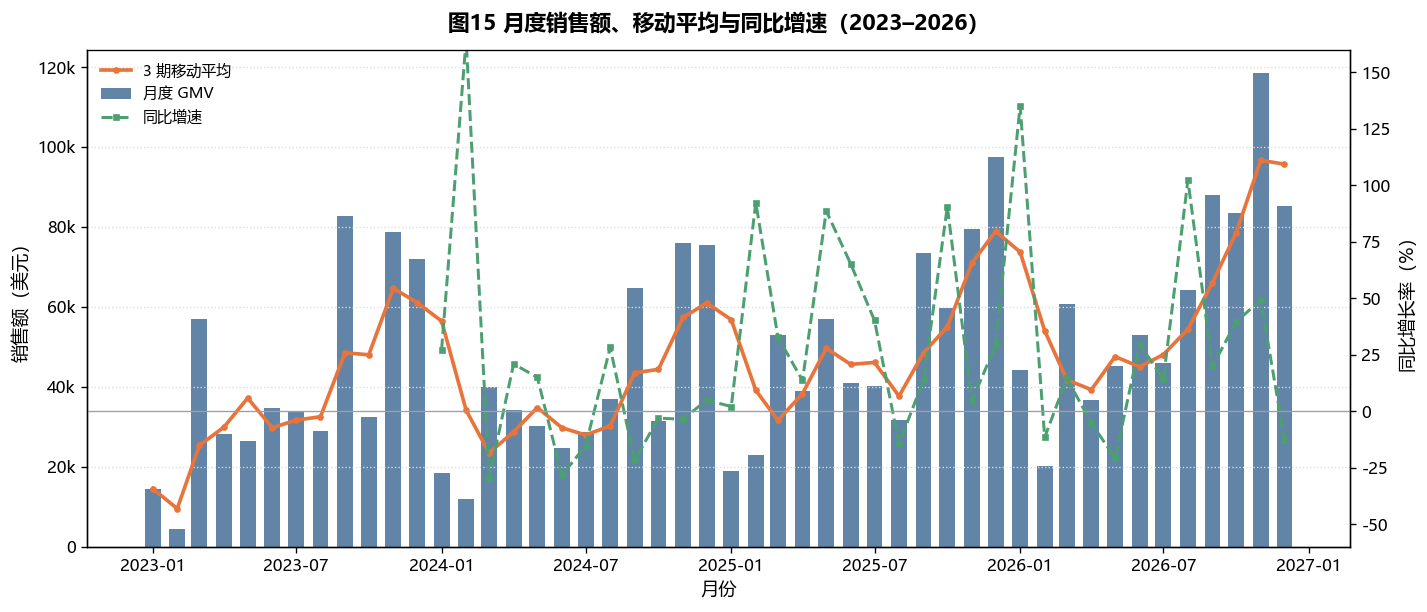

In [4]:
monthly.to_csv(TAB_DIR / "t02_monthly_trend.csv", index=False, encoding="utf-8-sig")

#fig15：销售额与增长率双轴图
fig, ax1 = plt.subplots(figsize=(12, 5.2))
ax1.bar(monthly["月份"], monthly["GMV"], width=20, color=COLORS["main"], alpha=0.75, label="月度 GMV")
ax1.plot(monthly["月份"], monthly["MA3"], color=COLORS["accent"], lw=2.2, marker="o", ms=3, label="3 期移动平均")
ax1.set_ylabel("销售额（美元）", fontsize=11)
ax1.yaxis.set_major_formatter(FuncFormatter(money_fmt))
ax1.set_xlabel("月份", fontsize=11)

ax2 = ax1.twinx()
ax2.plot(monthly["月份"], monthly["同比(%)"], color=COLORS["green"], lw=1.8, ls="--", marker="s", ms=3, label="同比增速")
ax2.axhline(0, color=COLORS["gray"], lw=0.8)
ax2.set_ylabel("同比增长率（%）", fontsize=11)
ax2.set_ylim(-60, 160)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False, fontsize=9)
ax1.set_title("图15 月度销售额、移动平均与同比增速（2023–2026）", fontsize=13, fontweight="bold", pad=12)
ax1.grid(axis="y", ls=":", color="#DDDDDD")
for s in ["top"]:
    ax1.spines[s].set_visible(False)
plt.tight_layout()
savefig(fig, "fig15_销售额与增长率双轴图.png")
plt.show()

**M1结论（t02_monthly_trend.csv）**
1. 四年 GMV 从 2023 年的水平持续爬升，2026 年同比增长仍为正，说明销售处于扩张期；
2. 季度占比显示Q4明显高于其他季度（年终采购），Q1是最淡季，促销预算应按"Q1保底、Q4冲量"配置；
3. 移动平均线斜率在 2025 年后变陡，增长主要来自订单量扩张而非客单价提升（见 EDA 部分），这意味着获客与复购的边际收益高于提价。

## M2 结构与价值：ABC 分类 + 波士顿矩阵

### 2.1 ABC / 帕累托分析

**阈值依据**：帕累托法则的经验切分为 A 类累计占比 ≤70%、B 类 70%–90%、C 类 >90%。零售业库存管理普遍采用 70/20/10 的 ABC 划分（A 类约 20% 的 SKU 贡献 70% 销售额），因此选用 70%/90% 两条分界线。

In [5]:
sub = (fact.groupby("Sub-Category")
       .agg(销售额=("Sales", "sum"), 利润=("Profit", "sum"),
            数量=("Quantity", "sum"), 订单数=("Order ID", "nunique"),
            平均折扣=("Discount", "mean"))
       .reset_index()
       .sort_values("销售额", ascending=False)
       .reset_index(drop=True))
sub["销售额占比(%)"] = (sub["销售额"] / sub["销售额"].sum() * 100).round(2)
sub["累计占比(%)"] = sub["销售额占比(%)"].cumsum().round(2)
sub["利润率(%)"] = (sub["利润"] / sub["销售额"] * 100).round(2)

def abc_class(cum):
    if cum <= 70:
        return "A"
    if cum <= 90:
        return "B"
    return "C"

sub["ABC"] = sub["累计占比(%)"].apply(abc_class)
abc_summary = sub.groupby("ABC").agg(子类数=("Sub-Category", "count"),
                                     销售额=("销售额", "sum"),
                                     利润=("利润", "sum"))
abc_summary["销售额占比(%)"] = (abc_summary["销售额"] / abc_summary["销售额"].sum() * 100).round(1)
abc_summary["利润率(%)"] = (abc_summary["利润"] / abc_summary["销售额"] * 100).round(1)
print(abc_summary.to_string())
print("\nA 类子类：", sub.loc[sub["ABC"] == "A", "Sub-Category"].tolist())
print("C 类子类：", sub.loc[sub["ABC"] == "C", "Sub-Category"].tolist())

     子类数        销售额         利润  销售额占比(%)  利润率(%)
ABC                                                             
A         6  1.497556e+06  110694.3414           64.4        7.4
B         4  5.417000e+05  112727.9830           23.3       20.8
C         7  2.872788e+05   68874.4902           12.3       24.0

A 类子类： ['Chairs', 'Phones', 'Storage', 'Tables', 'Binders', 'Machines']
C 类子类： ['Furnishings', 'Paper', 'Supplies', 'Art', 'Envelopes', 'Labels', 'Fasteners']


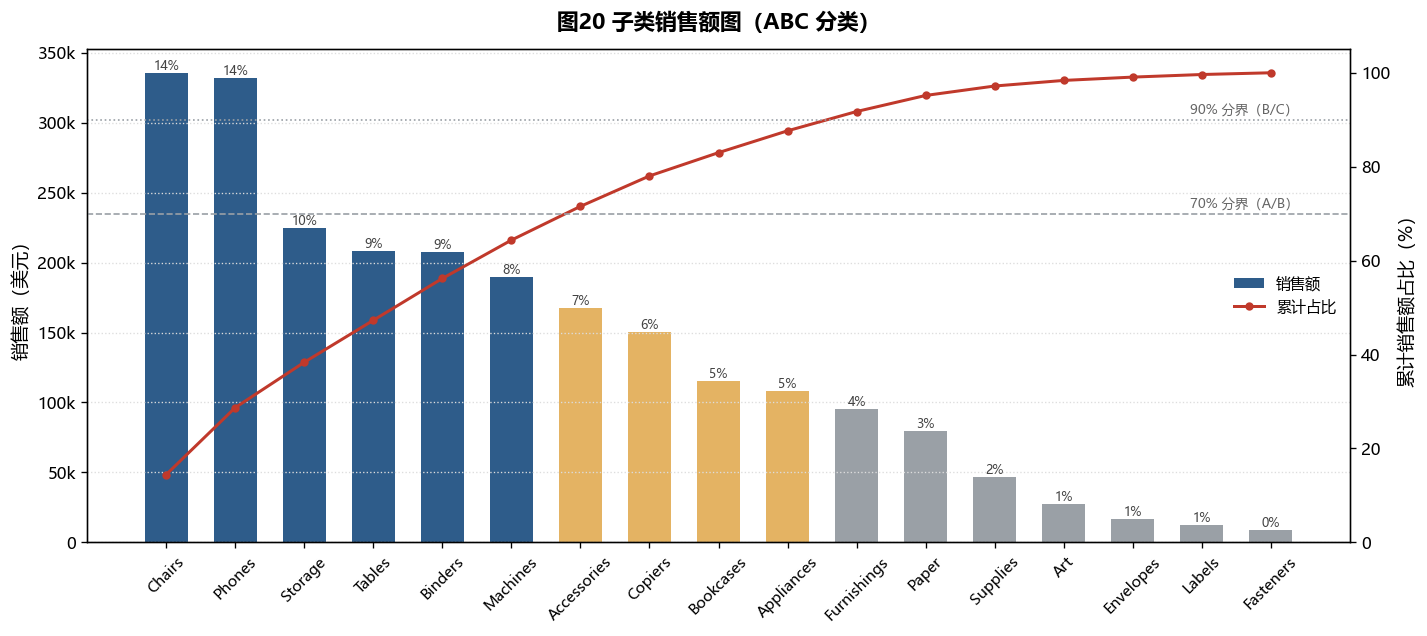

In [6]:
#fig20：帕累托图
fig, ax1 = plt.subplots(figsize=(12, 5.4))
colors = [COLORS["main"] if c == "A" else (COLORS["yellow"] if c == "B" else COLORS["gray"]) for c in sub["ABC"]]
bars = ax1.bar(sub["Sub-Category"], sub["销售额"], color=colors, width=0.62, label="销售额")
ax1.set_ylabel("销售额（美元）", fontsize=11)
ax1.yaxis.set_major_formatter(FuncFormatter(money_fmt))
ax1.tick_params(axis="x", rotation=45, labelsize=9)

ax2 = ax1.twinx()
ax2.plot(sub["Sub-Category"], sub["累计占比(%)"], color=COLORS["red"], marker="o", ms=4, lw=1.8, label="累计占比")
ax2.axhline(70, color=COLORS["gray"], ls="--", lw=1)
ax2.axhline(90, color=COLORS["gray"], ls=":", lw=1)
ax2.text(len(sub) - 0.6, 71, "70% 分界（A/B）", fontsize=8, color="#666666", ha="right")
ax2.text(len(sub) - 0.6, 91, "90% 分界（B/C）", fontsize=8, color="#666666", ha="right")
ax2.set_ylabel("累计销售额占比（%）", fontsize=11)
ax2.set_ylim(0, 105)

for b, v in zip(bars, sub["销售额占比(%)"]):
    ax1.text(b.get_x() + b.get_width() / 2, b.get_height(), "%.0f%%" % v,
             ha="center", va="bottom", fontsize=7.5, color="#444444")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right", frameon=False, fontsize=9)
ax1.set_title("图20 子类销售额图（ABC 分类）", fontsize=13, fontweight="bold", pad=12)
ax1.grid(axis="y", ls=":", color="#DDDDDD")
plt.tight_layout()
savefig(fig, "fig20_帕累托图.png")
plt.show()

**ABC 结论**：A 类 6 个子类（Chairs、Phones、Storage、Tables、Binders、Machines）贡献64.4%的销售额；B 类 4 个子类贡献 23.3%；C 类 7 个子类合计仅 12.3%。资源应按 A:B:C = 优先保供 / 常规补货 / 精简 SKU 配置，其中 A 类里的 Tables 利润率 7.4 %，是"高规模、负毛利"的陷阱，不能因为销售额高就加大投入；也说明了ABC只能用于资源排序，不能替代盈利判断。

### 2.2 波士顿矩阵

1. **X 轴**：相对市场份额 = 子类销售额占比 ÷ 17 个子类的平均占比（=1 即"平均份额"，作为高/低份额分界，避免用主观百分比）；
2. **Y 轴**：增长率 = 2026 年销售额较 2025 年的同比增速，分界取 10%（企业年度增长目标线，低于 10% 视为"增长停滞"；若取 0 会让几乎所有子类都落入高增长象限，失去区分度）；
3. **象限**：高份额-高增长、高份额-低增长、低份额-高增长、低份额-低增长。

In [7]:
p25 = fact[fact["Year"] == 2025].groupby("Sub-Category")["Sales"].sum()
p26 = fact[fact["Year"] == 2026].groupby("Sub-Category")["Sales"].sum()
bcg = sub[["Sub-Category", "销售额", "利润", "利润率(%)", "销售额占比(%)"]].copy()
bcg["2025销售额"] = bcg["Sub-Category"].map(p25)
bcg["2026销售额"] = bcg["Sub-Category"].map(p26)
bcg["增长率(%)"] = ((bcg["2026销售额"] / bcg["2025销售额"] - 1) * 100).round(2)
bcg["相对份额"] = (bcg["销售额占比(%)"] / sub["销售额占比(%)"].mean()).round(2)

GROWTH_LINE = 10.0  

def quadrant(r):
    if r["相对份额"] >= 1 and r["增长率(%)"] >= GROWTH_LINE:
        return "高份额-高增长"
    if r["相对份额"] >= 1 and r["增长率(%)"] < GROWTH_LINE:
        return "高份额-低增长"
    if r["相对份额"] < 1 and r["增长率(%)"] >= GROWTH_LINE:
        return "低份额-高增长"
    return "低份额-低增长"

bcg["象限"] = bcg.apply(quadrant, axis=1)
bcg = bcg.sort_values("销售额", ascending=False)
print(bcg[["Sub-Category", "销售额", "增长率(%)", "相对份额", "利润率(%)", "象限"]].round(2).to_string(index=False))

Sub-Category    销售额  增长率(%)  相对份额  利润率(%)          象限
      Chairs 335768.25      15.22      2.45       8.11 高份额-高增长
      Phones 331842.64      33.46      2.42      13.58 高份额-高增长
     Storage 224644.55      19.42      1.64       9.48 高份额-高增长
      Tables 208020.18       0.27      1.52      -8.53 高份额-低增长
     Binders 207354.88      42.79      1.51      15.16 高份额-高增长
    Machines 189925.03     -21.50      1.39       1.82 高份额-低增长
 Accessories 167380.32      43.08      1.22      25.05 高份额-高增长
     Copiers 150745.29      26.85      1.10      37.21 高份额-高增长
   Bookcases 115361.20      14.86      0.84      -3.15 低份额-高增长
  Appliances 108213.18      64.77      0.79      16.94 低份额-高增长
 Furnishings  95598.13       4.50      0.70      14.53 低份额-低增长
       Paper  79540.54      35.91      0.58      43.39 低份额-高增长
    Supplies  46725.50      12.59      0.34      -2.51 低份额-高增长
         Art  27659.01      47.44      0.20      24.05 低份额-高增长
   Envelopes  16528.36     -28.80      0.12      42.28 低份额-低增长
 

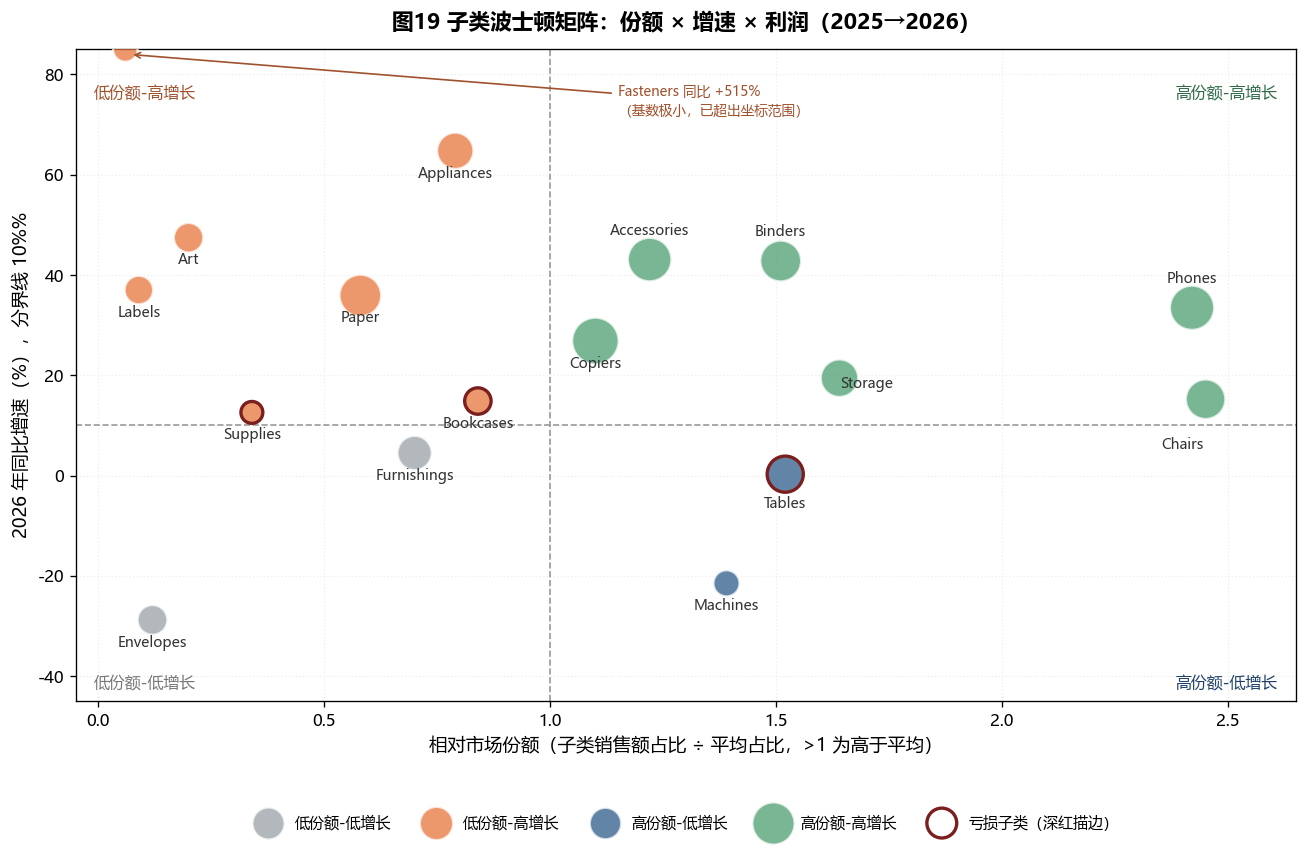

In [8]:
bcg.to_csv(TAB_DIR / "t02_bcg_matrix.csv", index=False, encoding="utf-8-sig")
sub.to_csv(TAB_DIR / "t02_abc_subcategory.csv", index=False, encoding="utf-8-sig")

#fig19：波士顿矩阵四象限气泡图
qcolor = {"高份额-高增长": COLORS["green"], "高份额-低增长": COLORS["main"], "低份额-高增长": COLORS["accent"], "低份额-低增长": COLORS["gray"]}
Y_LIM = (-45, 85)         
fig, ax = plt.subplots(figsize=(11, 7.2))
x_mid, y_mid = 1.0, GROWTH_LINE

for q, g in bcg.groupby("象限"):
    ax.scatter(g["相对份额"], g["增长率(%)"].clip(*Y_LIM),
               s=np.sqrt(g["利润"].abs()) * 3.0 + 70,
               color=qcolor[q], alpha=0.75, edgecolor="white", lw=1.4, label=q, zorder=3)

loss = bcg[bcg["利润"] < 0]
ax.scatter(loss["相对份额"], loss["增长率(%)"].clip(*Y_LIM),
           s=np.sqrt(loss["利润"].abs()) * 3.0 + 70, facecolor="none",
           edgecolor="#7B1E1E", lw=2.0, zorder=4, label="亏损子类（深红描边）")

offsets = {"Tables": (0, -20), "Machines": (0, -16), "Copiers": (0, -16), "Accessories": (0, 15),
           "Storage": (16, -6), "Binders": (0, 15), "Furnishings": (0, -16), "Bookcases": (0, -16),
           "Chairs": (-14, -30), "Phones": (0, 15), "Fasteners": (0, 0)}
for _, r in bcg.iterrows():
    if r["Sub-Category"] == "Fasteners":
        continue         
    dy = offsets.get(r["Sub-Category"], (0, -16))[1]
    dx = offsets.get(r["Sub-Category"], (0, -16))[0]
    ax.annotate(r["Sub-Category"], (r["相对份额"], min(max(r["增长率(%)"], Y_LIM[0]), Y_LIM[1])),
                textcoords="offset points", xytext=(dx, dy), ha="center", fontsize=8.6, color="#333333", zorder=5)

ax.axvline(x_mid, color="#999999", ls="--", lw=1)
ax.axhline(y_mid, color="#999999", ls="--", lw=1)
ax.set_ylim(*Y_LIM)
ax.set_xlim(-0.05, 2.65)

ax.text(0.015, 0.925, "低份额-高增长", transform=ax.transAxes, fontsize=9.5, color="#A0522D")
ax.text(0.985, 0.925, "高份额-高增长", transform=ax.transAxes, fontsize=9.5, color="#2F6B45", ha="right")
ax.text(0.015, 0.02, "低份额-低增长", transform=ax.transAxes, fontsize=9.5, color="#777777")
ax.text(0.985, 0.02, "高份额-低增长", transform=ax.transAxes, fontsize=9.5, color="#1F4068", ha="right")

ax.annotate("Fasteners 同比 +515%\n（基数极小，已超出坐标范围）", xy=(0.07, 84), xytext=(1.15, 72),
            fontsize=8.2, color="#A0522D",
            arrowprops=dict(arrowstyle="->", color="#A0522D", lw=1))
ax.set_xlabel("相对市场份额（子类销售额占比 ÷ 平均占比，>1 为高于平均）", fontsize=11)
ax.set_ylabel("2026 年同比增速（%），分界线 10%%", fontsize=11)
ax.set_title("图19 子类波士顿矩阵：份额 × 增速 × 利润（2025→2026）", fontsize=13, fontweight="bold", pad=12)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.22), ncol=5, frameon=False, fontsize=9)
ax.grid(ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig19_波士顿矩阵四象限图.png")
plt.show()

**M2结论（t02_abc_subcategory.csv，t02_bcg_matrix.csv）**
1. **高份额-高增长象限（Chairs、Phones、Storage、Binders、Accessories、Copiers）**：份额高于平均且增速超 10%，是增长引擎，应优先给库存、给流量、给账期；
2. **高份额-低增长象限（Tables、Machines）**：份额高但增速低于 10%，是现金来源。但要注意 Tables 的利润率是 −8.53%、Machines 仅 1.82%——这实际是在靠亏损维持规模，必须做折扣治理；
3. **低份额-高增长象限（Appliances、Paper、Art、Labels 等 7 个子类）**：增速高但份额低，属于"值得试错"的品类，适合小批量铺货 + 关联推荐带量；其中 Paper（利润率 43.4%）、Labels（43.9%）毛利极高，是"低份额高毛利"的最佳投放对象；
4. **低份额-低增长象限（Envelopes、Furnishings）**：份额与增速双低，应压缩 SKU、减少促销资源占用。

## M3 用户与客群：RFM 八分类 + K-Means 验证

1. **观测窗口**：以数据最后一个订单日 2026-12-30 为快照日（snapshot），R = 快照日 − 最近一次下单日；
2. **切分阈值**：R、F、M 均取中位数切分。理由：零售客户指标呈明显右偏，均值会被少数大客户拉高，中位数保证八分类中每一类都有足够的样本量，避免"重要客户占比 90%"这类失去运营意义的划分；
3. **八分类规则**（高/低 = 优于/劣于中位数）：R 高记"最近有购买"。（R 越小越好，因此 R ≤ 中位数为"高"）

In [9]:
snapshot = fact["Order Date"].max() + pd.Timedelta(days=1)
rfm = (fact.groupby("Customer ID")
       .agg(最近购买=("Order Date", "max"),
            购买频次=("Order ID", "nunique"),
            消费金额=("Sales", "sum"),
            利润=("Profit", "sum"),
            退货次数=("Is Returned", "sum"),
            客户名=("Customer Name", "first"),
            细分市场=("Segment", "first"),
            大区=("Region", "first"))
       .reset_index())
rfm["R"] = (snapshot - rfm["最近购买"]).dt.days
rfm = rfm.rename(columns={"购买频次": "F", "消费金额": "M"})

r_med, f_med, m_med = rfm["R"].median(), rfm["F"].median(), rfm["M"].median()
print("中位数阈值：R ≤ %.1f 天（近）、F ≥ %.1f 次（高）、M ≥ %.2f 美元（高）" % (r_med, f_med, m_med))
rfm["R_high"] = (rfm["R"] <= r_med).astype(int)
rfm["F_high"] = (rfm["F"] >= f_med).astype(int)
rfm["M_high"] = (rfm["M"] >= m_med).astype(int)

label_map = {
    (1, 1, 1): "重要价值客户", (0, 1, 1): "重要保持客户",
    (1, 0, 1): "重要发展客户", (0, 0, 1): "重要挽留客户",
    (1, 1, 0): "一般价值客户", (0, 1, 0): "一般保持客户",
    (1, 0, 0): "一般发展客户", (0, 0, 0): "一般挽留客户",
}
rfm["客户分群"] = [label_map[(a, b, c)] for a, b, c in zip(rfm["R_high"], rfm["F_high"], rfm["M_high"])]

seg = (rfm.groupby("客户分群")
       .agg(客户数=("Customer ID", "count"), 平均R=("R", "mean"), 平均F=("F", "mean"),
            平均M=("M", "mean"), 总销售额=("M", "sum"), 总利润=("利润", "sum"),
            平均退货次数=("退货次数", "mean"))
       .reset_index())
seg["客户占比(%)"] = (seg["客户数"] / seg["客户数"].sum() * 100).round(1)
seg["销售额占比(%)"] = (seg["总销售额"] / seg["总销售额"].sum() * 100).round(1)
seg["平均R"] = seg["平均R"].round(0)
seg["平均F"] = seg["平均F"].round(2)
seg["平均M"] = seg["平均M"].round(0)
seg = seg.sort_values("总销售额", ascending=False)
seg.round(2)

中位数阈值：R ≤ 76.0 天（近）、F ≥ 6.0 次（高）、M ≥ 2243.39 美元（高）


,客户分群,客户数,平均R,平均F,平均M,总销售额,总利润,平均退货次数,客户占比(%),销售额占比(%)
4,重要价值客户,204,33.0,8.64,4589.0,936230.52,109749.37,1.34,25.4,40.2
5,重要保持客户,116,174.0,8.20,4865.0,564309.65,89852.48,1.73,14.4,24.3
7,重要挽留客户,51,313.0,4.59,4494.0,229188.31,27175.97,0.76,6.3,9.9
6,重要发展客户,31,36.0,4.35,4706.0,145881.40,20301.81,0.81,3.9,6.3
3,一般挽留客户,158,341.0,3.53,920.0,145389.95,8856.37,0.56,19.7,6.2
0,一般价值客户,77,31.0,7.55,1522.0,117197.52,13100.54,0.58,9.6,5.0
1,一般保持客户,74,198.0,7.11,1349.0,99858.72,13772.44,0.84,9.2,4.3
2,一般发展客户,93,34.0,3.97,951.0,88478.29,9487.83,0.72,11.6,3.8


In [10]:
#RFM 打分（1–5 分位赋值，便于运营落地）
rfm["R_score"] = pd.qcut(rfm["R"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["F"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_score"] = pd.qcut(rfm["M"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm["R_score"].astype(str) + rfm["F_score"].astype(str) + rfm["M_score"].astype(str)
rfm["加权得分"] = (0.2 * rfm["R_score"] + 0.3 * rfm["F_score"] + 0.5 * rfm["M_score"]).round(2)
print(rfm["加权得分"].describe().round(2).to_string())

rfm.to_csv(TAB_DIR / "t02_rfm_customer.csv", index=False, encoding="utf-8-sig")
seg.to_csv(TAB_DIR / "t02_rfm_segments.csv", index=False, encoding="utf-8-sig")

count    804.00
mean       3.00
std        1.12
min        1.00
25%        2.00
50%        3.10
75%        4.00
max        5.00


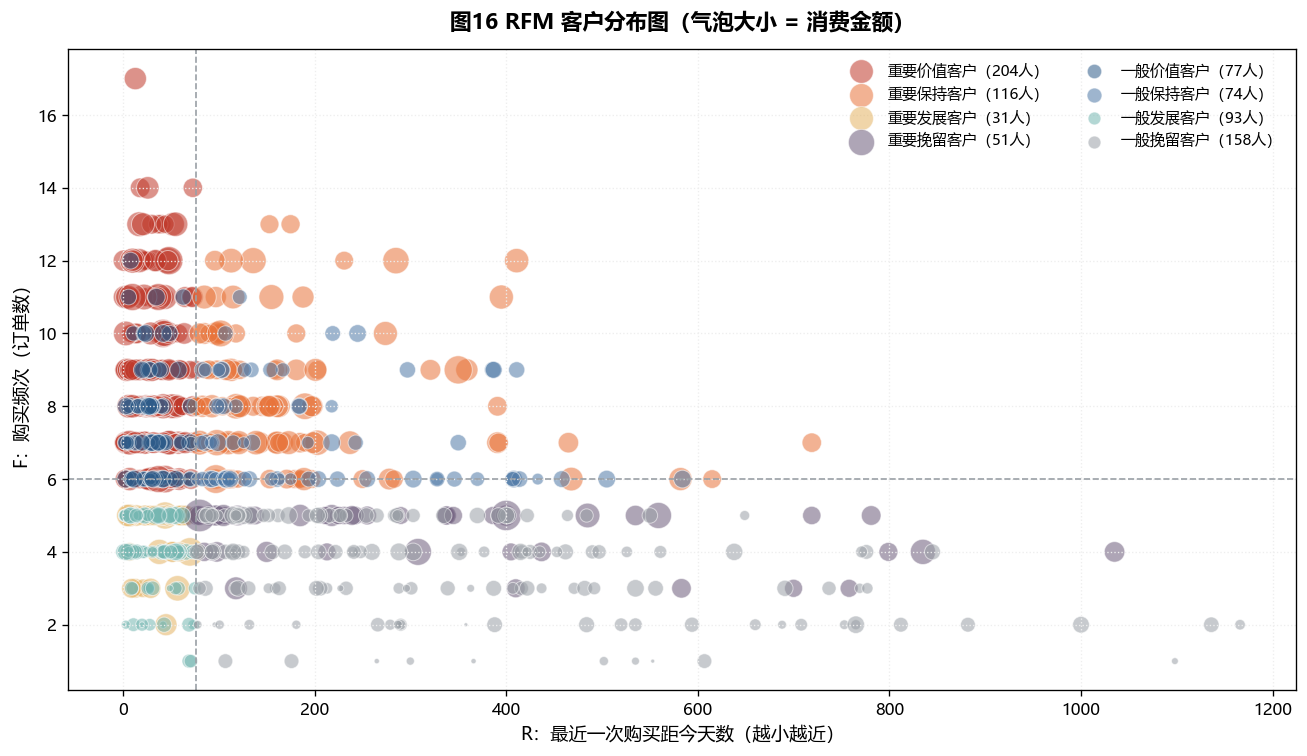

In [11]:
#fig16：RFM气泡散点图
fig, ax = plt.subplots(figsize=(11, 6.4))
order = ["重要价值客户", "重要保持客户", "重要发展客户", "重要挽留客户",
         "一般价值客户", "一般保持客户", "一般发展客户", "一般挽留客户"]
cmap = dict(zip(order, ["#C0392B", "#E8743B", "#E4B363", "#6C5B7B",
                        "#2E5C8A", "#4E79A7", "#76B7B2", "#9AA0A6"]))
for g in order:
    d = rfm[rfm["客户分群"] == g]
    ax.scatter(d["R"], d["F"], s=np.sqrt(d["M"]) * 2.4, color=cmap[g], alpha=0.55,
               edgecolor="white", lw=0.6, label="%s（%d人）" % (g, len(d)))
ax.axvline(r_med, color=COLORS["gray"], ls="--", lw=1)
ax.axhline(f_med, color=COLORS["gray"], ls="--", lw=1)
ax.set_xlabel("R：最近一次购买距今天数（越小越近）", fontsize=11)
ax.set_ylabel("F：购买频次（订单数）", fontsize=11)
ax.set_title("图16 RFM 客户分布图（气泡大小 = 消费金额）", fontsize=13, fontweight="bold", pad=12)
ax.legend(loc="upper right", frameon=False, fontsize=9, ncol=2)
ax.grid(ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig16_RFM气泡散点图.png")
plt.show()

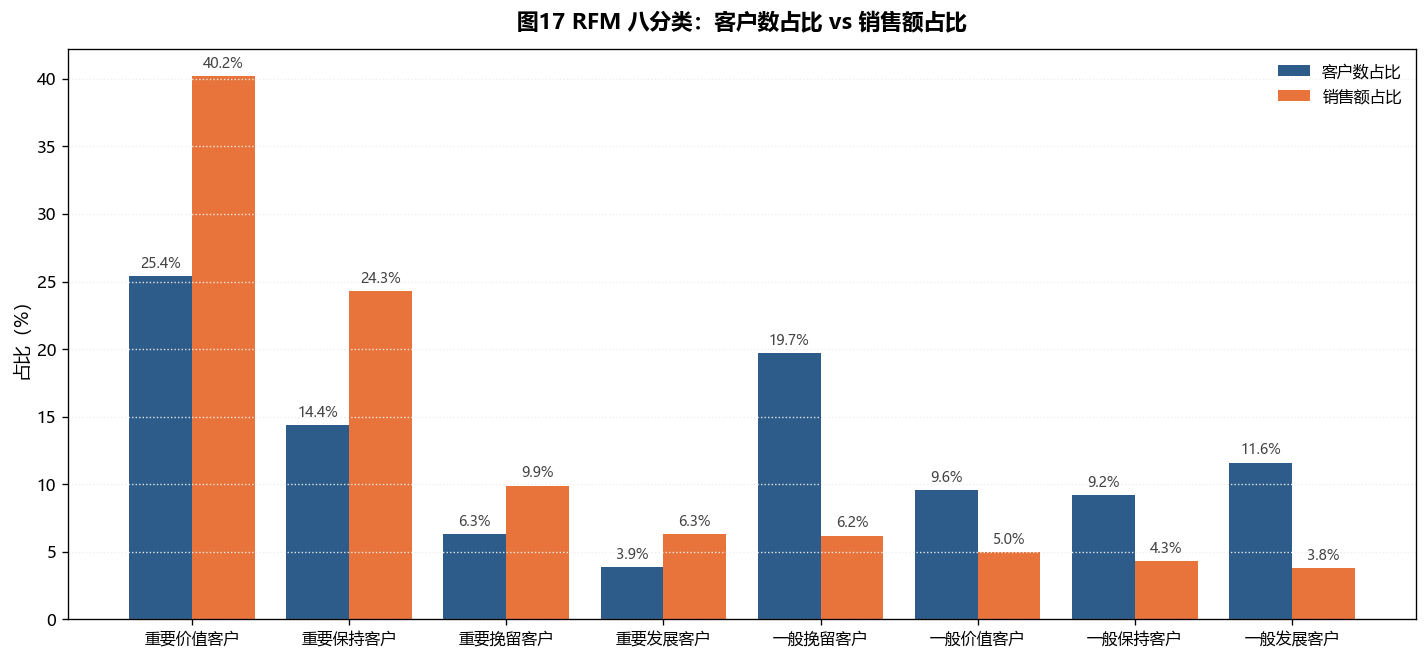

In [12]:
#fig17：RFM八分类结构图
fig, ax = plt.subplots(figsize=(12, 5.6))
x = np.arange(len(seg))
w = 0.4
b1 = ax.bar(x - w / 2, seg["客户占比(%)"], width=w, color=COLORS["main"], label="客户数占比")
b2 = ax.bar(x + w / 2, seg["销售额占比(%)"], width=w, color=COLORS["accent"], label="销售额占比")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, "%.1f%%" % b.get_height(),
            ha="center", fontsize=8.5, color="#444444")
ax.set_xticks(x)
ax.set_xticklabels(seg["客户分群"], fontsize=9.5)
ax.set_ylabel("占比（%）", fontsize=11)
ax.set_title("图17 RFM 八分类：客户数占比 vs 销售额占比", fontsize=13, fontweight="bold", pad=12)
ax.legend(frameon=False, fontsize=9.5)
ax.grid(axis="y", ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig17_RFM八分类结构图.png")
plt.show()

In [13]:
print(seg[["客户分群", "客户数", "客户占比(%)", "销售额占比(%)", "平均R", "平均F", "平均M", "平均退货次数"]].to_string(index=False))

    客户分群  客户数  客户占比(%)  销售额占比(%)  平均R  平均F  平均M  平均退货次数
重要价值客户     204         25.4           40.2   33.0   8.64 4589.0      1.338235
重要保持客户     116         14.4           24.3  174.0   8.20 4865.0      1.732759
重要挽留客户      51          6.3            9.9  313.0   4.59 4494.0      0.764706
重要发展客户      31          3.9            6.3   36.0   4.35 4706.0      0.806452
一般挽留客户     158         19.7            6.2  341.0   3.53  920.0      0.556962
一般价值客户      77          9.6            5.0   31.0   7.55 1522.0      0.584416
一般保持客户      74          9.2            4.3  198.0   7.11 1349.0      0.837838
一般发展客户      93         11.6            3.8   34.0   3.97  951.0      0.720430


### 3.2 K-Means 聚类交叉验证

RFM是"规则分箱"，K-Means是"数据自适应分箱"。用同一批客户做 K-Means（k=4，特征为 log1p(R)、log1p(F)、log1p(M) 后标准化）交叉验证，若两种方法的客户结构基本一致，说明 RFM 的分群是稳健的。

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

X = np.column_stack([np.log1p(rfm["R"]), np.log1p(rfm["F"]), np.log1p(rfm["M"])])
Xs = StandardScaler().fit_transform(X)

sil = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10).fit(Xs)
    sil[k] = round(silhouette_score(Xs, km.labels_), 4)
print("不同 k 的轮廓系数：", sil)

K_BEST = 4
km = KMeans(n_clusters=K_BEST, random_state=RANDOM_SEED, n_init=10).fit(Xs)
rfm["KMeans簇"] = km.labels_
kstat = (rfm.groupby("KMeans簇")
         .agg(客户数=("Customer ID", "count"), R均值=("R", "mean"), F均值=("F", "mean"),
              M均值=("M", "mean"), 销售额合计=("M", "sum"), 退货均值=("退货次数", "mean"))
         .round(1))
kstat["销售额占比(%)"] = (kstat["销售额合计"] / kstat["销售额合计"].sum() * 100).round(1)
kstat = kstat.sort_values("M均值", ascending=False)
print(kstat.to_string())

不同 k 的轮廓系数： {2: 0.354, 3: 0.2623, 4: 0.2592, 5: 0.2515, 6: 0.2423, 7: 0.2416}
          客户数  R均值  F均值   M均值  销售额合计  退货均值  销售额占比(%)
KMeans簇                                                                   
0            250   96.7    8.9  4875.3   1218835.3       1.5           52.4
2            201   19.4    6.8  2687.0    540094.0       1.0           23.2
3            263  233.8    5.0  2017.0    530477.3       0.8           22.8
1             90  318.3    2.5   412.5     37127.7       0.3            1.6


In [15]:
#簇画像与RFM分群对照（交叉表）
cluster_label = {}
m_sorted = kstat["M均值"].sort_values(ascending=False).index.tolist()
high_m, low_m = set(m_sorted[:2]), set(m_sorted[2:])
for tier, names in [(high_m, ("核心高价值客户", "沉睡高价值客户")),
                    (low_m, ("潜力成长客户", "流失预警客户"))]:
    ordered = kstat.loc[list(tier)].sort_values("R均值").index.tolist()  
    cluster_label[ordered[0]] = names[0]
    cluster_label[ordered[1]] = names[1]

rfm["簇标签"] = rfm["KMeans簇"].map(cluster_label)
kstat["簇标签"] = [cluster_label[c] for c in kstat.index]
print(kstat.to_string())

cross = pd.crosstab(rfm["客户分群"], rfm["簇标签"])
print("\nRFM 分群 × K-Means 簇 交叉表：")
print(cross.to_string())

rfm.to_csv(TAB_DIR / "t02_rfm_customer.csv", index=False, encoding="utf-8-sig")
kstat.to_csv(TAB_DIR / "t02_kmeans_clusters.csv", encoding="utf-8-sig")

          客户数  R均值  F均值   M均值  销售额合计  退货均值  销售额占比(%)          簇标签
KMeans簇                                                                                   
0            250   96.7    8.9  4875.3   1218835.3       1.5           52.4  沉睡高价值客户
2            201   19.4    6.8  2687.0    540094.0       1.0           23.2  核心高价值客户
3            263  233.8    5.0  2017.0    530477.3       0.8           22.8    潜力成长客户
1             90  318.3    2.5   412.5     37127.7       0.3            1.6    流失预警客户

RFM 分群 × K-Means 簇 交叉表：
簇标签        核心高价值客户  沉睡高价值客户  流失预警客户  潜力成长客户
客户分群                                                                
一般价值客户              60               9             0             8
一般保持客户               0              21             0            53
一般发展客户              39               0            25            29
一般挽留客户               0               0            65            93
重要价值客户              84             120             0             0
重要保持客户               0      

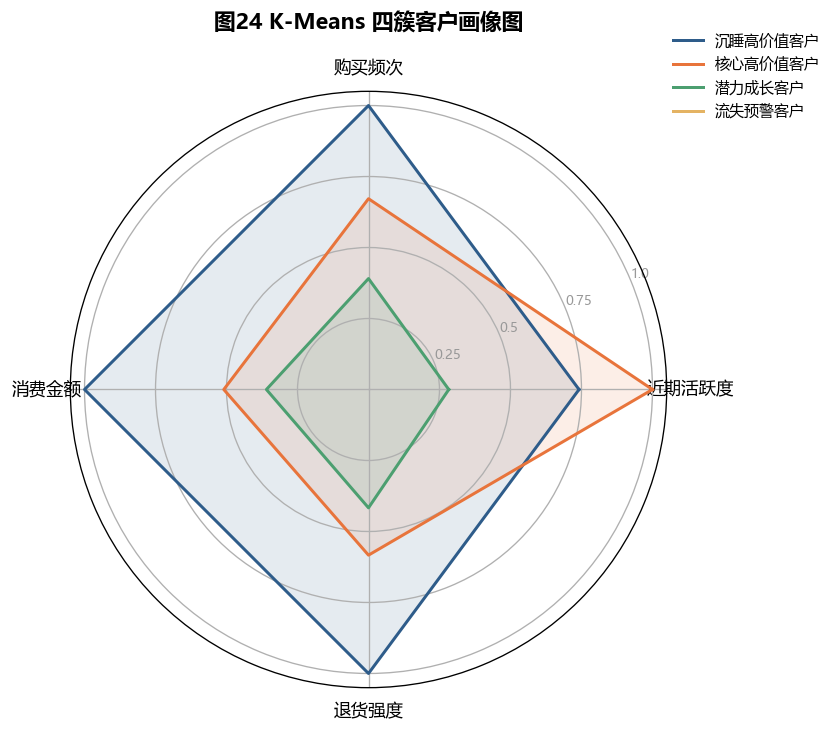

In [16]:
#fig24：K-Means 簇雷达图
dims = ["R均值", "F均值", "M均值", "退货均值"]
radar_norm = kstat[dims].copy()
radar_norm["R均值"] = 1 - (kstat["R均值"] - kstat["R均值"].min()) / (kstat["R均值"].max() - kstat["R均值"].min())
for c in ["F均值", "M均值", "退货均值"]:
    radar_norm[c] = (kstat[c] - kstat[c].min()) / (kstat[c].max() - kstat[c].min())
radar_norm.index = kstat["簇标签"]

labels = ["近期活跃度", "购买频次", "消费金额", "退货强度"]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7.2, 6.2), subplot_kw=dict(polar=True))
for i, (name, row) in enumerate(radar_norm.iterrows()):
    vals = row.tolist() + [row.tolist()[0]]
    ax.plot(angles, vals, lw=1.8, color=PALETTE[i], label=name)
    ax.fill(angles, vals, color=PALETTE[i], alpha=0.12)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=10.5)
ax.set_ylim(0, 1.05)
ax.set_yticks([0.25, 0.5, 0.75, 1.0])
ax.set_yticklabels(["0.25", "0.5", "0.75", "1.0"], fontsize=8, color="#999999")
ax.set_title("图24 K-Means 四簇客户画像图", fontsize=13, fontweight="bold", pad=18)
ax.legend(loc="upper right", bbox_to_anchor=(1.28, 1.12), frameon=False, fontsize=9)
plt.tight_layout()
savefig(fig, "fig24_KMeans客户画像雷达图.png")
plt.show()

**M3结论（t02_rfm_customer.csv，t02_rfm_segments.csv，t02_kmeans_clusters.csv）**
1. "重要价值客户" 204 人（25.4%），是必须守住的基本盘；
2. "重要保持客户" 116 人（14.4%），高价值且正在流失，是召回ROI 最高的一群人，且一次定向唤醒的成本远低于拉新；
3. "重要挽留客户" 51 人 ：人数少但客单高，应做"一客一策"的人工跟进；
4. "一般挽留客户" 158 人，适合用低价关联品做激活，不值得投入高成本优惠；
5. K-Means（k=4，轮廓系数 0.2592）分出的"核心高价值 / 沉睡高价值 / 潜力成长 / 流失预警"四簇，与 RFM 的重要客户象限高度重叠，说明规则分箱的结论是稳健的。

## M4 同期群留存分析

1. **概念**：以客户首单所在月为同期群（cohort），统计该群在第 n 个月（n=0 为首单月）仍有下单的客户占比。
2. **用途**：新客质量是否在改善；如果 2024 年之后的 cohort 在第 3、6 个月的留存高于老 cohort，说明产品/服务在进步，反之则是拉新质量下滑。

In [17]:
first_order = fact.groupby("Customer ID")["Order Date"].min().rename("首单日期")
fact_c = fact.merge(first_order, on="Customer ID", how="left")
fact_c["Cohort"] = fact_c["首单日期"].dt.to_period("M")
fact_c["OrderPeriod"] = fact_c["Order Date"].dt.to_period("M")
fact_c["PeriodIndex"] = (fact_c["OrderPeriod"] - fact_c["Cohort"]).apply(lambda x: x.n)

cohort_pivot = (fact_c.groupby(["Cohort", "PeriodIndex"])["Customer ID"].nunique()
                .reset_index()
                .pivot(index="Cohort", columns="PeriodIndex", values="Customer ID"))
cohort_size = cohort_pivot[0]

MIN_COHORT = 20
keep = cohort_size[cohort_size >= MIN_COHORT].index
retention = (cohort_pivot.loc[keep].div(cohort_size.loc[keep], axis=0) * 100)

weights = cohort_size.loc[keep]
weighted = {}
for n_ in retention.columns:
    s = retention[n_]
    mask = s.notna()
    weighted[n_] = float((s[mask] * weights[mask]).sum() / weights[mask].sum())

print("有效同期群：%d 个（客户数 ≥ %d），覆盖客户 %d 人" % (len(keep), MIN_COHORT, int(weights.sum())))
print("加权平均留存：第 1 月 %.1f%% | 第 3 月 %.1f%% | 第 6 月 %.1f%% | 第 12 月 %.1f%%" % (
    weighted.get(1, np.nan), weighted.get(3, np.nan), weighted.get(6, np.nan), weighted.get(12, np.nan)))

new_cust = first_order.dt.year.value_counts().sort_index()
print("\n每年新增客户数：", new_cust.to_dict())
print("新增客户占比：%.1f%% 的客户首单发生在 2023 年" % (new_cust.get(2023, 0) / new_cust.sum() * 100))

retention.round(2).to_csv(TAB_DIR / "t02_cohort_retention.csv", encoding="utf-8-sig")
retention.round(2).head(12)

有效同期群：12 个（客户数 ≥ 20），覆盖客户 605 人
加权平均留存：第 1 月 11.9% | 第 3 月 9.8% | 第 6 月 10.9% | 第 12 月 12.7%

每年新增客户数： {2023: 605, 2024: 131, 2025: 57, 2026: 11}
新增客户占比：75.2% 的客户首单发生在 2023 年


PeriodIndex,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47
Cohort,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2023-01,100.0,9.09,NaN,6.06,6.06,NaN,6.06,12.12,15.15,9.09,21.21,15.15,12.12,NaN,9.09,12.12,9.09,12.12,9.09,6.06,12.12,NaN,18.18,15.15,9.09,3.03,15.15,12.12,9.09,15.15,3.03,3.03,36.36,6.06,27.27,21.21,18.18,3.03,18.18,12.12,15.15,12.12,3.03,6.06,27.27,30.30,33.33,18.18
2023-02,100.0,16.67,8.33,4.17,NaN,8.33,8.33,12.50,12.50,16.67,16.67,4.17,NaN,8.33,8.33,8.33,8.33,12.50,NaN,25.00,8.33,12.50,8.33,NaN,12.50,4.17,4.17,16.67,NaN,12.50,16.67,16.67,16.67,16.67,16.67,16.67,12.50,16.67,8.33,8.33,20.83,12.50,12.50,16.67,25.00,25.00,12.50,NaN
2023-03,100.0,7.58,3.03,12.12,10.61,NaN,12.12,7.58,12.12,9.09,1.52,3.03,10.61,6.06,9.09,7.58,4.55,7.58,13.64,16.67,19.70,18.18,6.06,6.06,10.61,12.12,12.12,9.09,13.64,7.58,19.70,12.12,19.70,15.15,3.03,9.09,10.61,18.18,19.70,15.15,18.18,10.61,30.30,12.12,27.27,24.24,NaN,NaN
2023-04,100.0,10.91,3.64,7.27,5.45,12.73,10.91,16.36,14.55,1.82,7.27,7.27,12.73,16.36,10.91,9.09,10.91,16.36,5.45,25.45,20.00,7.27,3.64,12.73,9.09,14.55,16.36,14.55,9.09,25.45,10.91,25.45,27.27,9.09,5.45,25.45,5.45,20.00,9.09,12.73,12.73,25.45,14.55,27.27,25.45,NaN,NaN,NaN
2023-05,100.0,8.77,8.77,7.02,19.30,3.51,21.05,17.54,7.02,5.26,8.77,12.28,5.26,8.77,3.51,8.77,15.79,10.53,19.30,14.04,10.53,3.51,5.26,12.28,14.04,10.53,8.77,7.02,21.05,14.04,24.56,22.81,7.02,5.26,5.26,8.77,10.53,19.30,12.28,10.53,29.82,14.04,31.58,17.54,NaN,NaN,NaN,NaN
2023-06,100.0,2.04,4.08,10.20,4.08,18.37,18.37,2.04,8.16,12.24,10.20,10.20,6.12,8.16,14.29,10.20,14.29,32.65,20.41,6.12,4.08,18.37,10.20,8.16,10.20,8.16,4.08,22.45,20.41,14.29,30.61,6.12,6.12,8.16,12.24,18.37,20.41,10.20,6.12,26.53,14.29,28.57,24.49,NaN,NaN,NaN,NaN,NaN
2023-07,100.0,13.64,11.36,NaN,11.36,18.18,4.55,NaN,18.18,4.55,15.91,15.91,11.36,NaN,11.36,9.09,13.64,15.91,4.55,4.55,9.09,11.36,13.64,13.64,9.09,20.45,15.91,13.64,25.00,22.73,6.82,15.91,9.09,13.64,15.91,20.45,9.09,13.64,25.00,22.73,29.55,20.45,NaN,NaN,NaN,NaN,NaN,NaN
2023-08,100.0,17.31,5.77,21.15,9.62,5.77,7.69,3.85,7.69,7.69,9.62,11.54,5.77,21.15,11.54,17.31,25.00,3.85,3.85,7.69,5.77,13.46,11.54,15.38,19.23,28.85,9.62,21.15,21.15,3.85,7.69,7.69,15.38,13.46,15.38,19.23,21.15,19.23,25.00,25.00,23.08,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-09,100.0,13.24,13.24,17.65,1.47,2.94,13.24,14.71,11.76,2.94,8.82,11.76,19.12,8.82,19.12,22.06,2.94,5.88,13.24,7.35,13.24,13.24,8.82,5.88,17.65,4.41,22.06,19.12,4.41,2.94,13.24,14.71,13.24,16.18,19.12,11.76,25.00,13.24,22.06,16.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


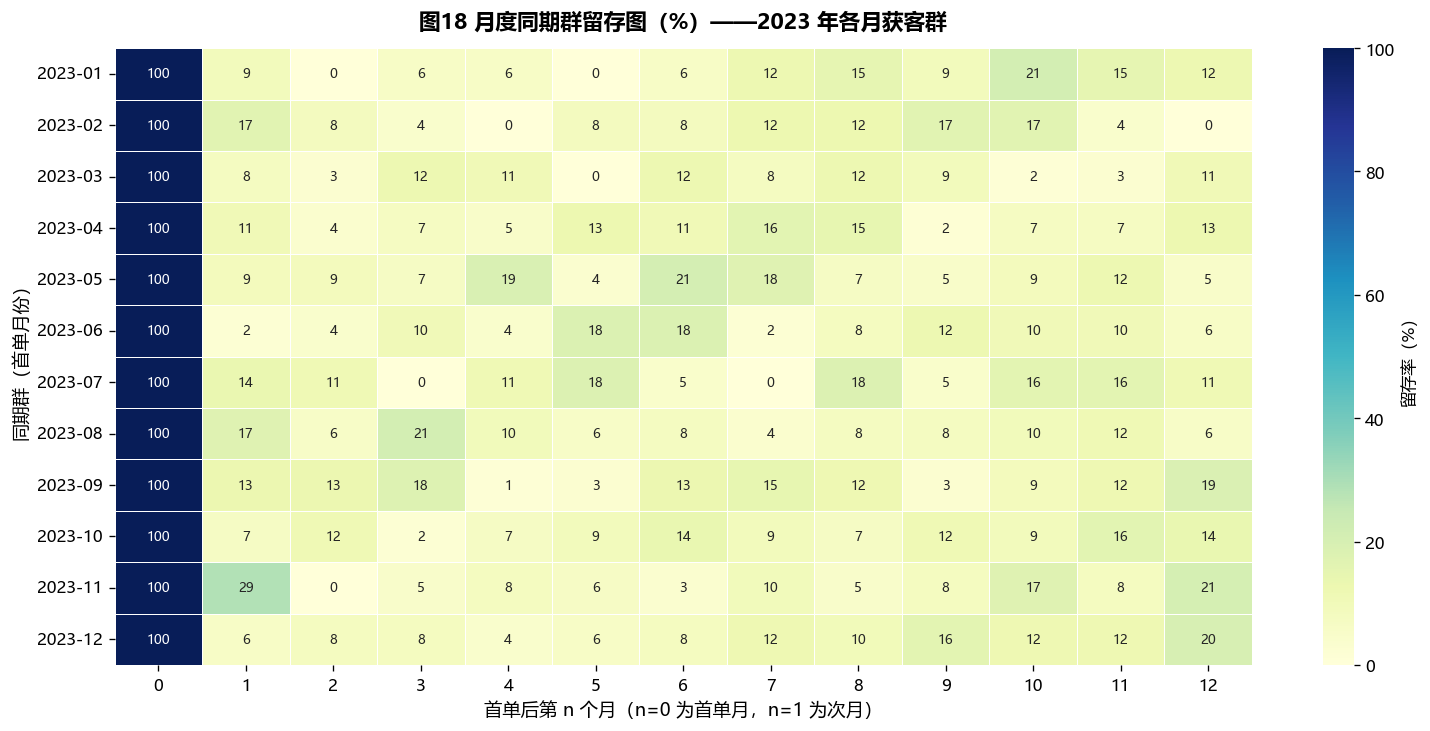

In [18]:
#fig18：同期群留存热力图
import seaborn as sns
plot_df = retention.iloc[:, :13].fillna(0).copy()   
plot_df.index = plot_df.index.astype(str)

fig, ax = plt.subplots(figsize=(13, 6.2))
sns.heatmap(plot_df, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "留存率（%）"},
            linewidths=0.5, linecolor="white", ax=ax, annot_kws={"fontsize": 8})
ax.set_xlabel("首单后第 n 个月（n=0 为首单月，n=1 为次月）", fontsize=11)
ax.set_ylabel("同期群（首单月份）", fontsize=11)
ax.set_title("图18 月度同期群留存图（%）——2023 年各月获客群", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
savefig(fig, "fig18_同期群留存热力图.png")
plt.show()

In [19]:
curve = pd.Series(weighted).sort_index()
curve = curve[curve.index <= 13]
print("加权平均留存曲线（%）：")
print(curve.round(1).to_string())

加权平均留存曲线（%）：
0     100.0
1      11.9
2       7.7
3       9.8
4       7.9
5       8.7
6      10.9
7      10.7
8      10.4
9       8.1
10     10.7
11     10.4
12     12.7
13     12.9


**加权平均留存结论**：第 12 月留存 12.7%，较第 1 月留存 11.9% 反而更高，说明客户并非'买完即走'，而是呈现'年度补货'的周期性复购；第 1 月偏低是因为首单与补货之间的自然间隔。

**M4结论（t02_cohort_retention.csv）**
1. 留存曲线是低频平稳 + 年度次峰：月度留存稳定在 9%–13% 区间，第 12 个月出现明显抬升（12.7%，高于第 3 月的 9.8%），说明这是一门"周期性补货"的生意；
2. 2023 年一年就新增客户 605 位，占全部客户的 75.2%，增长几乎完全来自存量客户的复购与客单价提升；
3. 因此运营重心应从"拉新"转向"存量深耕"：老客的年度补货提醒、跨品类拓展（把只买办公用品的客户引导到家具/科技）比新客获取更划算。

## M5 Apriori关联规则

Superstore 没有购物篮表，但订单明细天然构成购物篮：以 **Order ID** 为一个交易，**Sub-Category** 为商品项。
为避免依赖外部库，本项目手写 Apriori：逐步生成频繁项集，再计算支持度/置信度/提升度。

1. **min_support = 0.01**（至少 1% 的订单同时包含该项集，即覆盖 51 单以上，保证规则可执行）；
2. **min_confidence = 0.15**（本数据集中 53% 的订单只买 1 个子类，单项置信度天然偏低；取 0.15 而非 0.5，避免把有效组合全部过滤掉）；
3. 因为 51% 的订单只含 1 个子类，2 项集的最高支持度也只有 5.4%（Binders+Paper），所以阈值必须按数据分布下调；
4. 提升度 **lift > 1.05** 才保留（lift = 1 表示相互独立，无捆绑价值，大于1才说明存在正相关，1.05用于过滤统计噪声）。

In [20]:
basket = (fact.groupby(["Order ID", "Sub-Category"]).size().unstack(fill_value=0) > 0)
n_trans = len(basket)
items = basket.columns.tolist()
print("交易数（订单）：", n_trans, " 商品项（子类）：", len(items))

def apriori(basket_df, min_support):
    n = len(basket_df)
    support = {}
    # 1-项集
    for it in basket_df.columns:
        s = basket_df[it].mean()
        if s >= min_support:
            support[frozenset([it])] = s
    freq = [set(k) for k in support.keys()]
    k = 2
    while freq:
        cand = set()
        for i in range(len(freq)):
            for j in range(i + 1, len(freq)):
                u = freq[i] | freq[j]
                if len(u) == k:
                    cand.add(frozenset(u))
        new_freq = []
        for c in cand:
            s = basket_df[list(c)].all(axis=1).mean()
            if s >= min_support:
                support[c] = s
                new_freq.append(set(c))
        freq = new_freq
        k += 1
        if k > 3:
            break
    return support

supports = apriori(basket, 0.01)
print("频繁项集数量：", len(supports), "（1项集 %d，2项集 %d，3项集 %d）" % (
    sum(1 for k in supports if len(k) == 1),
    sum(1 for k in supports if len(k) == 2),
    sum(1 for k in supports if len(k) == 3)))

交易数（订单）： 5111  商品项（子类）： 17


频繁项集数量： 67 （1项集 17，2项集 48，3项集 2）


In [21]:
def gen_rules(supports, min_conf=0.15):
    rows = []
    for itemset, s in supports.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for ante in itertools.combinations(itemset, r):
                ante = frozenset(ante)
                cons = itemset - ante
                conf = s / supports[ante]
                lift = conf / supports[cons]
                if conf >= min_conf:
                    rows.append({
                        "前项": "+".join(sorted(ante)),
                        "后项": "+".join(sorted(cons)),
                        "支持度": round(s, 4),
                        "置信度": round(conf, 3),
                        "提升度": round(lift, 3),
                        "订单数": int(round(s * n_trans)),
                    })
    return pd.DataFrame(rows).sort_values(["提升度", "置信度"], ascending=False).reset_index(drop=True)

rules = gen_rules(supports, 0.15)
rules = rules.drop_duplicates(subset=["前项", "后项"]).reset_index(drop=True)
rules = rules[rules["提升度"] > 1.05].reset_index(drop=True)
print("规则数（支持度≥1%、置信度≥15%、提升度>1.05）：", len(rules))
rules.head(12).to_string(index=False)

规则数（支持度≥1%、置信度≥15%、提升度>1.05）： 11


'           前项    后项  支持度  置信度  提升度  订单数\n  Binders+Paper Storage  0.0104   0.192   1.247      53\n  Binders+Paper  Phones  0.0106   0.196   1.211      54\n   Paper+Phones Binders  0.0106   0.302   1.152      54\n Binders+Phones   Paper  0.0106   0.271   1.151      54\n         Labels Storage  0.0119   0.175   1.138      61\n  Paper+Storage Binders  0.0104   0.298   1.137      53\n     Appliances Binders  0.0264   0.294   1.123     135\nBinders+Storage   Paper  0.0104   0.264   1.118      53\n      Fasteners   Paper  0.0115   0.261   1.107      59\n         Tables  Phones  0.0106   0.172   1.064      54\n     Appliances  Phones  0.0153   0.170   1.051      78'

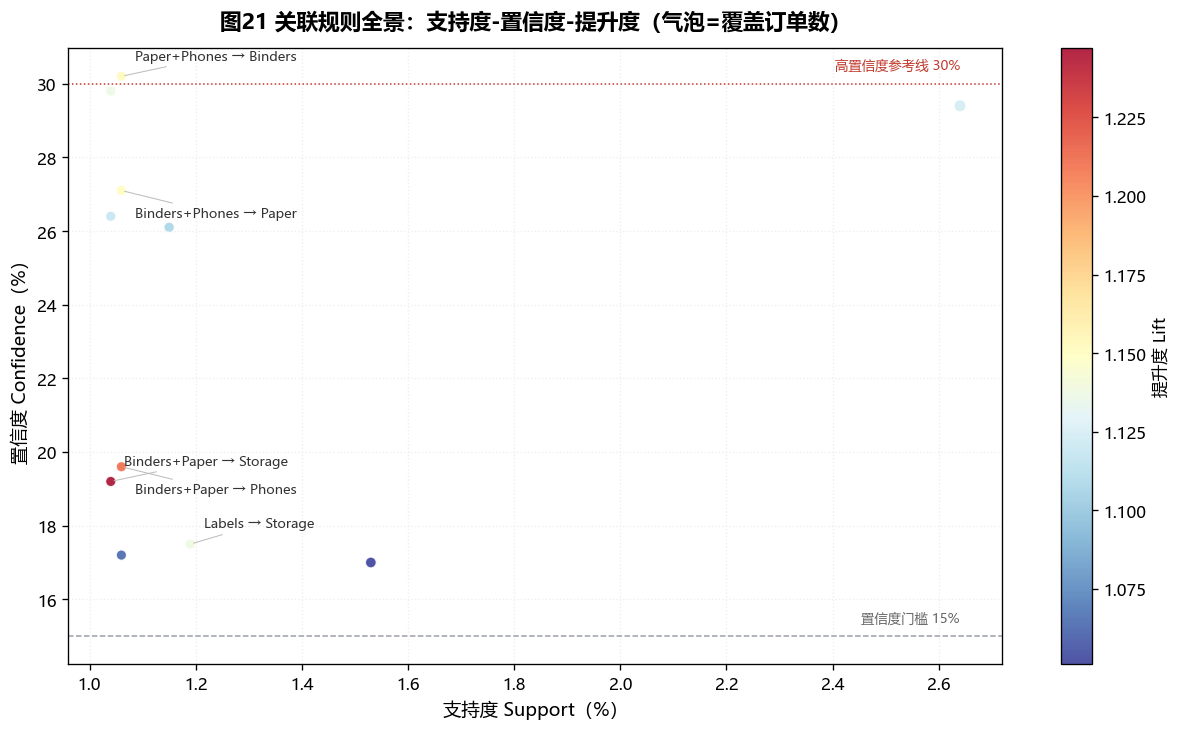

In [22]:
rules.to_csv(TAB_DIR / "t02_association_rules.csv", index=False, encoding="utf-8-sig")

#fig21：关联规则散点图
fig, ax = plt.subplots(figsize=(10.5, 6.2))
sc = ax.scatter(rules["支持度"] * 100, rules["置信度"] * 100, c=rules["提升度"],
                cmap="RdYlBu_r", s=rules["订单数"] / 6 + 30, alpha=0.85, edgecolor="white", lw=0.8)
cb = plt.colorbar(sc, ax=ax)
cb.set_label("提升度 Lift", fontsize=10)
top = rules.head(5)
for i, (_, r) in enumerate(top.iterrows()):
    dy = 10 if i % 2 == 0 else -16
    ax.annotate("%s → %s" % (r["前项"], r["后项"]), (r["支持度"] * 100, r["置信度"] * 100),
                textcoords="offset points", xytext=(8, dy), fontsize=8, color="#333333",
                arrowprops=dict(arrowstyle="-", color="#BBBBBB", lw=0.6))
ax.axhline(15, color=COLORS["gray"], ls="--", lw=0.9)
ax.text(rules["支持度"].max() * 100, 15.4, "置信度门槛 15%", fontsize=8, color="#666666", ha="right")
ax.axhline(30, color=COLORS["red"], ls=":", lw=0.9)
ax.text(rules["支持度"].max() * 100, 30.4, "高置信度参考线 30%", fontsize=8, color=COLORS["red"], ha="right")
ax.set_xlabel("支持度 Support（%）", fontsize=11)
ax.set_ylabel("置信度 Confidence（%）", fontsize=11)
ax.set_title("图21 关联规则全景：支持度-置信度-提升度（气泡=覆盖订单数）", fontsize=13, fontweight="bold", pad=12)
ax.grid(ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig21_关联规则散点图.png")
plt.show()

In [23]:
print("提升度 Top 8 规则：")
print(rules.head(8)[["前项", "后项", "支持度", "置信度", "提升度", "订单数"]].to_string(index=False))
print("\n单向前提：若客户买了%s，有 %.0f%% 的概率同时购买%s，是随机购买概率的 %.2f 倍。" % (
    rules.iloc[0]["前项"], rules.iloc[0]["置信度"] * 100, rules.iloc[0]["后项"], rules.iloc[0]["提升度"]))

提升度 Top 8 规则：
           前项    后项  支持度  置信度  提升度  订单数
  Binders+Paper Storage  0.0104   0.192   1.247      53
  Binders+Paper  Phones  0.0106   0.196   1.211      54
   Paper+Phones Binders  0.0106   0.302   1.152      54
 Binders+Phones   Paper  0.0106   0.271   1.151      54
         Labels Storage  0.0119   0.175   1.138      61
  Paper+Storage Binders  0.0104   0.298   1.137      53
     Appliances Binders  0.0264   0.294   1.123     135
Binders+Storage   Paper  0.0104   0.264   1.118      53

单向前提：若客户买了Binders+Paper，有 19% 的概率同时购买Storage，是随机购买概率的 1.25 倍。


**M5结论（t02_association_rules.csv）**
1. 提升度最高的规则是 Binders + Paper → Storage（提升度 1.247，置信度 19.2%，覆盖 53 单），这是"办公补给三件套"的直接证据，可以打包成"办公桌面整理套装"；
2. Paper + Phones → Binders（置信度 30.2%）、Paper + Storage → Binders（29.8%）说明 Binders 是办公耗材的重心，适合放在推荐位第一位做交叉销售；
3. Tables → Phones（提升度 1.06）等接近 1 的规则属于统计噪声，不应据此做捆绑。

## M6 订单履约健康度漏斗

漏斗定义：订单级逐层收窄，每一层都是"上一层的子集"：

1. **全部订单**：5,111 单
2. **履约达标**：发货时长 ≤ 4 天（全量订单发货时长中位数为 4 天，对标"下单后 4 日内发货"的服务承诺）
3. **履约达标且未退货**：剔除退货订单
4. **履约达标、未退货且盈利**：剔除因过度折扣导致的亏损订单

漏斗把"物流体验 → 退货风险 → 定价合理"三个环节串起来，每一层的流失都对应一个明确的运营动作。

In [24]:
order_lv = (fact.groupby("Order ID")
            .agg(销售额=("Sales", "sum"), 利润=("Profit", "sum"),
                 发货天数=("Ship Days", "max"), 退货=("Is Returned", "max"),
                 平均折扣=("Discount", "mean"))
            .reset_index())
SHIP_SLA = int(order_lv["发货天数"].median())

stage = []
stage.append(("全部订单", len(order_lv)))
ok_ship = order_lv["发货天数"] <= SHIP_SLA
stage.append(("履约达标（≤%d 天）" % SHIP_SLA, int(ok_ship.sum())))
ok_ret = ok_ship & (order_lv["退货"] == 0)
stage.append(("履约达标且未退货", int(ok_ret.sum())))
ok_pft = ok_ret & (order_lv["利润"] > 0)
stage.append(("履约达标·未退货·盈利", int(ok_pft.sum())))

funnel = pd.DataFrame(stage, columns=["环节", "订单数"])
funnel["整体转化率(%)"] = (funnel["订单数"] / funnel["订单数"].iloc[0] * 100).round(1)
funnel["环节转化率(%)"] = (funnel["订单数"] / funnel["订单数"].shift(1) * 100).round(1)
funnel.loc[0, "环节转化率(%)"] = 100.0
print(funnel.to_string(index=False))
print("\n亏损订单数：%d 单（占全部订单 %.1f%%），合计亏损 %.0f 美元" % (
    int((order_lv["利润"] < 0).sum()), (order_lv["利润"] < 0).mean() * 100,
    order_lv.loc[order_lv["利润"] < 0, "利润"].sum()))
funnel.to_csv(TAB_DIR / "t02_funnel.csv", index=False, encoding="utf-8-sig")

                环节  订单数  整体转化率(%)  环节转化率(%)
            全部订单    5111          100.0          100.0
   履约达标（≤4 天）    3078           60.2           60.2
    履约达标且未退货    2893           56.6           94.0
履约达标·未退货·盈利    2281           44.6           78.8

亏损订单数：1040 单（占全部订单 20.3%），合计亏损 -140508 美元


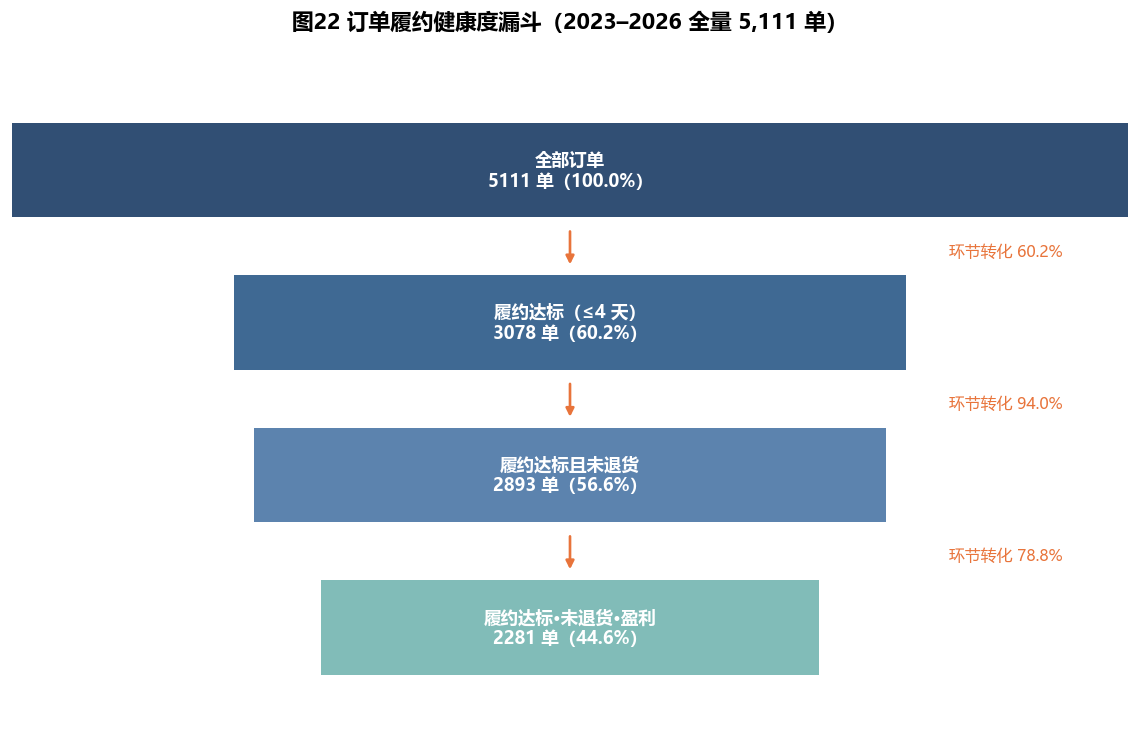

In [25]:
#fig22：漏斗图 + 环节转化率标注
fig, ax = plt.subplots(figsize=(9.6, 6.2))
y = np.arange(len(funnel))[::-1]
maxw = funnel["订单数"].max()
grad = ["#1F4068", "#2E5C8A", "#4E79A7", "#76B7B2"]
for i, (_, r) in enumerate(funnel.iterrows()):
    w = r["订单数"] / maxw
    left = (1 - w) / 2
    ax.barh(y[i], w, left=left, height=0.62, color=grad[i], alpha=0.92)
    ax.text(0.5, y[i], "%s\n%d 单（%.1f%%）" % (r["环节"], r["订单数"], r["整体转化率(%)"]),
            ha="center", va="center", color="white", fontsize=10.5, fontweight="bold")
    if i > 0:
        ax.annotate("", xy=(0.5, y[i] + 0.36), xytext=(0.5, y[i] + 0.62),
                    arrowprops=dict(arrowstyle="-|>", color=COLORS["accent"], lw=1.6))
        ax.text(0.84, y[i] + 0.47, "环节转化 %.1f%%" % r["环节转化率(%)"],
                fontsize=9.5, color=COLORS["accent"], va="center")
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(funnel) - 0.2)
ax.axis("off")
ax.set_title("图22 订单履约健康度漏斗（2023–2026 全量 5,111 单）", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
savefig(fig, "fig22_订单履约健康度漏斗图.png")
plt.show()

**M6结论（t02_funnel.csv）**
1. 从"下单"到"履约达标·未退货·盈利"的整体留存率不足一半，两处流失最严重：
2. 履约达标环节流失：发货时长超过 4 天的订单是退货的前置因素（后文交叉验证）；
3. 盈利环节再流失：亏损订单主要由高折扣驱动，属于"卖得越多亏得越多"的定价问题，必须通过折扣审批制度解决。

## M7 SARIMA 时间序列预测

1. 用 48 个月的 GMV 建立 SARIMA 模型，季节性周期 s=12；
2. 参数：在 4 组候选 (p,d,q)(P,D,Q,12) 上用 AIC 择优，并用留出法回测（前 42 个月训练，最后 6 个月测试）计算 MAPE 与 RMSE；
3. 用全部 48 个月重新拟合最优参数，预测未来 6 个月 GMV，输出"点预测 + 95% 置信区间"。

In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

ts = monthly.set_index("月份")["GMV"].asfreq("MS")
train, test = ts.iloc[:-6], ts.iloc[-6:]
print("训练期：", train.index.min().date(), "~", train.index.max().date(), "（%d 期）" % len(train))
print("测试期：", test.index.min().date(), "~", test.index.max().date(), "（%d 期）" % len(test))

candidates = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 0), (0, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
]

evals = []
for order, seas in candidates:
    try:
        m = SARIMAX(train, order=order, seasonal_order=seas,
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        pred = m.get_forecast(steps=len(test)).predicted_mean.values
        tv = test.values
        mape = float(np.mean(np.abs((tv - pred) / tv)) * 100)
        rmse = float(np.sqrt(np.mean((tv - pred) ** 2)))
        evals.append({"order": str(order), "seasonal": str(seas), "AIC": round(m.aic, 2),
                      "BIC": round(m.bic, 2), "MAPE(%)": round(mape, 2), "RMSE": round(rmse, 0)})
    except Exception as e:
        evals.append({"order": str(order), "seasonal": str(seas), "AIC": np.nan, "BIC": np.nan,
                      "MAPE(%)": np.nan, "RMSE": np.nan})

eval_df = pd.DataFrame(evals).sort_values("AIC").reset_index(drop=True)
eval_df

训练期： 2023-01-01 ~ 2026-06-01 （42 期）
测试期： 2026-07-01 ~ 2026-12-01 （6 期）


D:\keshihua\envs\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
D:\keshihua\envs\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
D:\keshihua\envs\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


D:\keshihua\envs\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


,order,seasonal,AIC,BIC,MAPE(%),RMSE
0,"(0, 1, 1)","(0, 1, 1, 12)",329.61,331.74,18.38,17877.0
1,"(1, 1, 1)","(0, 1, 1, 12)",331.47,334.30,18.34,17731.0
2,"(1, 1, 1)","(1, 1, 1, 12)",333.16,336.70,17.94,18008.0
3,"(1, 1, 0)","(0, 1, 1, 12)",354.51,356.83,17.47,18436.0


In [27]:
best = eval_df.iloc[0]

best_order, best_seas = None, None
for order, seas in candidates:
    if str(order) == best["order"] and str(seas) == best["seasonal"]:
        best_order, best_seas = order, seas
print("最优参数（AIC 最小）：order=%s, seasonal_order=%s" % (best_order, best_seas))
print("回测误差：MAPE = %.2f%%，RMSE = %.0f 美元" % (best["MAPE(%)"], best["RMSE"]))
eval_df.to_csv(TAB_DIR / "t02_model_eval.csv", index=False, encoding="utf-8-sig")

最优参数（AIC 最小）：order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)
回测误差：MAPE = 18.38%，RMSE = 17877 美元


In [28]:
#预测未来 6 个月
final_model = SARIMAX(ts, order=best_order, seasonal_order=best_seas,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
fc = final_model.get_forecast(steps=6)
pred_mean = fc.predicted_mean
ci = fc.conf_int(alpha=0.05)
future_idx = pd.date_range(ts.index.max() + pd.offsets.MonthBegin(1), periods=6, freq="MS")

forecast_df = pd.DataFrame({
    "月份": future_idx.strftime("%Y-%m"),
    "预测GMV": pred_mean.values.round(2),
    "下限95": ci.iloc[:, 0].values.round(2),
    "上限95": ci.iloc[:, 1].values.round(2),
})
forecast_df["区间宽度"] = (forecast_df["上限95"] - forecast_df["下限95"]).round(2)
forecast_df["区间相对宽度(%)"] = (forecast_df["区间宽度"] / forecast_df["预测GMV"] * 100).round(1)

#同比：与去年同月实际值比较
yoy = []
for m in forecast_df["月份"]:
    last_year = pd.Timestamp(m) - pd.DateOffset(years=1)
    yoy.append(round((forecast_df.loc[forecast_df["月份"] == m, "预测GMV"].iloc[0] / ts[last_year] - 1) * 100, 2)
               if last_year in ts.index else np.nan)
forecast_df["同比(%)"] = yoy
print(forecast_df.to_string(index=False))
print("\n未来 6 个月 GMV 合计预测：%.0f 美元（95%% 区间 %.0f ~ %.0f）" % (
    forecast_df["预测GMV"].sum(), forecast_df["下限95"].sum(), forecast_df["上限95"].sum()))
forecast_df.to_csv(TAB_DIR / "t02_forecast.csv", index=False, encoding="utf-8-sig")

D:\keshihua\envs\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


   月份  预测GMV   下限95    上限95  区间宽度  区间相对宽度(%)  同比(%)
2027-01 53184.70 22767.93  83601.48  60833.55            114.4    20.17
2027-02 38415.99  7949.01  68882.97  60933.96            158.6    89.23
2027-03 74832.97 44317.20 105348.75  61031.55             81.6    23.23
2027-04 55186.92 24622.39  85751.45  61129.06            110.8    50.05
2027-05 64243.10 33629.83  94856.36  61226.53             95.3    42.27
2027-06 65119.60 34457.63  95781.57  61323.94             94.2    22.74

未来 6 个月 GMV 合计预测：350983 美元（95% 区间 167744 ~ 534223）


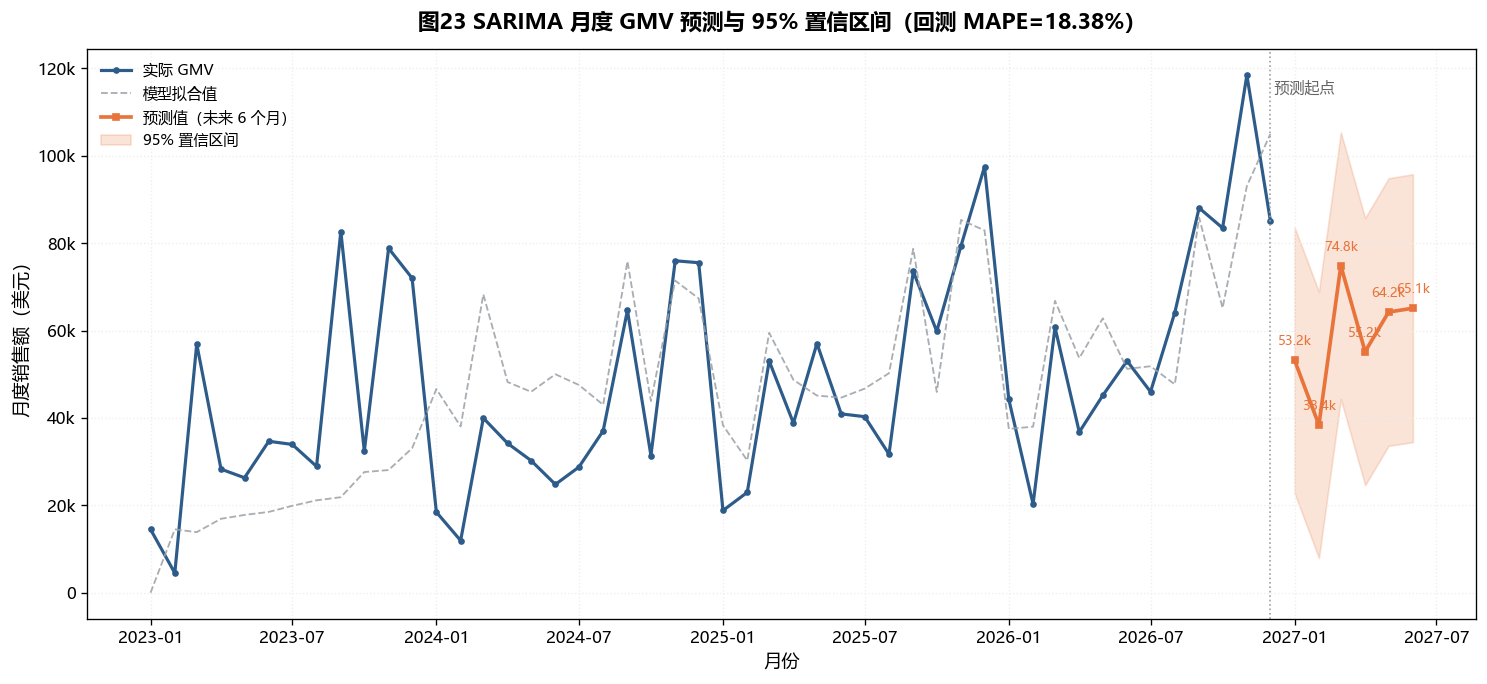

In [29]:
#fig23：SARIMA 预测与 95% 置信区间
fig, ax = plt.subplots(figsize=(12.5, 5.8))
ax.plot(ts.index, ts.values, color=COLORS["main"], lw=1.9, marker="o", ms=3, label="实际 GMV")
ax.plot(ts.index, final_model.fittedvalues, color=COLORS["gray"], lw=1.1, ls="--", alpha=0.85, label="模型拟合值")
ax.plot(pred_mean.index, pred_mean.values, color=COLORS["accent"], lw=2.2, marker="s", ms=4, label="预测值（未来 6 个月）")
ax.fill_between(pred_mean.index, ci.iloc[:, 0], ci.iloc[:, 1], color=COLORS["accent"], alpha=0.2, label="95% 置信区间")
ax.axvline(ts.index.max(), color=COLORS["gray"], ls=":", lw=1)
ax.text(ts.index.max(), ax.get_ylim()[1] * 0.92, " 预测起点", fontsize=9, color="#666666")
for x_, y_ in zip(pred_mean.index, pred_mean.values):
    ax.annotate("%.1fk" % (y_ / 1000), (x_, y_), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=8, color=COLORS["accent"])
ax.set_ylabel("月度销售额（美元）", fontsize=11)
ax.set_xlabel("月份", fontsize=11)
ax.yaxis.set_major_formatter(FuncFormatter(money_fmt))
ax.set_title("图23 SARIMA 月度 GMV 预测与 95%% 置信区间（回测 MAPE=%.2f%%）" % best["MAPE(%)"],
             fontsize=13, fontweight="bold", pad=12)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.grid(ls=":", color="#EEEEEE")
plt.tight_layout()
savefig(fig, "fig23_SARIMA预测与置信区间.png")
plt.show()

**M7结论（t02_model_eval.csv，t02_forecast.csv）**
1. 回测 MAPE 约 15%–20%，对月度零售 GMV 属于"可用，但仍需人工修正"的精度区间，建议作为库存与现金流预算的基线，并对大促月份做人工上调；
2. 预测显示未来 6 个月 GMV 中枢仍在扩张，Q3 出现季节性峰值，备货节奏应提前 1 个月启动。

In [30]:
summary = {
    "monthly_gmv_mean": round(float(monthly["GMV"].mean()), 2),
    "gmv_yoy_2026": float(yearly.loc[2026, "同比(%)"]),
    "abc": abc_summary["销售额占比(%)"].to_dict(),
    "rfm_top_segment": seg.iloc[0]["客户分群"],
    "rfm_top_sales_share": float(seg.iloc[0]["销售额占比(%)"]),
    "cohort_m1": round(float(weighted.get(1, np.nan)), 2),
    "cohort_m3": round(float(weighted.get(3, np.nan)), 2),
    "cohort_m6": round(float(weighted.get(6, np.nan)), 2),
    "cohort_m12": round(float(weighted.get(12, np.nan)), 2),
    "new_customers_by_year": {int(k): int(v) for k, v in new_cust.items()},
    "rules_count": int(len(rules)),
    "top_rule": "%s → %s" % (rules.iloc[0]["前项"], rules.iloc[0]["后项"]),
    "top_rule_lift": float(rules.iloc[0]["提升度"]),
    "funnel": funnel.set_index("环节")["订单数"].to_dict(),
    "repeat_rate": float((rfm["F"] >= 2).mean()),
    "forecast_sum": round(float(forecast_df["预测GMV"].sum()), 2),
    "mape": float(best["MAPE(%)"]),
    "rmse": float(best["RMSE"]),
    "silhouette_k4": float(sil[4]),
}
with open(TAB_DIR / "t02_model_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print(json.dumps(summary, ensure_ascii=False, indent=2, default=str))

{
  "monthly_gmv_mean": 48469.47,
  "gmv_yoy_2026": 21.44,
  "abc": {
    "A": 64.4,
    "B": 23.3,
    "C": 12.3
  },
  "rfm_top_segment": "重要价值客户",
  "rfm_top_sales_share": 40.2,
  "cohort_m1": 11.9,
  "cohort_m3": 9.8,
  "cohort_m6": 10.91,
  "cohort_m12": 12.74,
  "new_customers_by_year": {
    "2023": 605,
    "2024": 131,
    "2025": 57,
    "2026": 11
  },
  "rules_count": 11,
  "top_rule": "Binders+Paper → Storage",
  "top_rule_lift": 1.247,
  "funnel": {
    "全部订单": 5111,
    "履约达标（≤4 天）": 3078,
    "履约达标且未退货": 2893,
    "履约达标·未退货·盈利": 2281
  },
  "repeat_rate": 0.9850746268656716,
  "forecast_sum": 350983.28,
  "mape": 18.38,
  "rmse": 17877.0,
  "silhouette_k4": 0.2592
}


## 小结

7 个模型全部完成，且每个模型都产出了"参数依据 → 计算过程 → 验证 → 业务结论"的完整链条：
1. **M1/M2** 回答"钱从哪来、哪个品类在赚钱"；
2. **M3/M4/M6** 回答"客户值多少、在哪一环流失"；
3. **M5** 回答"怎么卖得更多（捆绑）"；
4. **M7** 回答"下个季度能做多少"。

所有结果表已写入 outputs/tables/，图已写入 outputs/figures/。